# Step 4 · 城市交通时空图编码器

本 Notebook 展示严格时间划分的数据窗口、训练完成的轻量 GCN + GRU、真实测试集评估、`E_st` 导出与 Figure 05–10。仅包含时空编码器，不包含语义编码或跨模态融合。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'pyproject.toml').exists())
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from urban_joint_encoder.data_loader import load_traffic_graph, SplitConfig, split_boundaries, fit_train_standardizer
from urban_joint_encoder.temporal_dataset import TrafficWindowDataset
from urban_joint_encoder.models import STForecastModel
from urban_joint_encoder.visualization import make_step4_figures
print('Project root:',ROOT)
print('Device: CPU')

Project root: /Users/daphne/Desktop/实习/PPT制作/联通项目/urban-joint-encoder
Device: CPU


## 1. 时间窗口与泄漏检查

划分依据是预测目标的原始行索引。每个样本仅使用目标前 12 行；验证和测试样本可使用紧邻分界线之前的真实历史上下文，但不使用任何未来行。标准化参数仅由训练原始行拟合。

In [2]:
traffic, adjacency, source_paths = load_traffic_graph(ROOT)
config = SplitConfig()
bounds = split_boundaries(len(traffic), config)
scaler = fit_train_standardizer(traffic, bounds['train'][1])
normalized = scaler.transform(traffic).astype(np.float32)
datasets = {
 'train': TrafficWindowDataset(normalized,12,bounds['train'][1],12),
 'validation': TrafficWindowDataset(normalized,bounds['validation'][0],bounds['validation'][1],12),
 'test': TrafficWindowDataset(normalized,bounds['test'][0],bounds['test'][1],12)}
display(pd.DataFrame({k:v.audit() for k,v in datasets.items()}).T)
print('Train-only scaler:',scaler)
assert datasets['validation'][0][2].item()==6048 and datasets['test'][0][2].item()==7344
assert datasets['test'][0][0].shape==(12,265,1)

,samples,target_row_range_inclusive,first_history_row_range_inclusive,last_history_row_range_inclusive,future_information_in_input
train,6036,"[12, 6047]","[0, 11]","[6035, 6046]",False
validation,1296,"[6048, 7343]","[6036, 6047]","[7331, 7342]",False
test,1296,"[7344, 8639]","[7332, 7343]","[8627, 8638]",False


Train-only scaler: Standardizer(mean=7.645755767822266, std=3.533116102218628, fitted_row_start=0, fitted_row_end_inclusive=6047)


## 2. 编码器与预测头

空间层使用 $D^{-1/2}(A+I)D^{-1/2}$ 聚合；随后对每个节点独立地沿 12 个时间步运行共享 GRU。编码器输出 `[B,265,32]`，独立线性预测头输出 `[B,265]`。

In [3]:
metrics = json.loads((ROOT/'outputs/metrics/st_training_metrics.json').read_text(encoding='utf-8'))
checkpoint = torch.load(ROOT/'outputs/models/st_encoder_best.pt',map_location='cpu',weights_only=True)
model = STForecastModel(torch.from_numpy(adjacency),hidden_dim=32)
model.load_state_dict(checkpoint['model_state_dict']); model.eval()
x = torch.zeros(2,12,265,1)
with torch.no_grad(): prediction, E_st_batch = model(x)
print('Input:',tuple(x.shape),'E_st:',tuple(E_st_batch.shape),'Prediction:',tuple(prediction.shape))
print('Parameters:',sum(p.numel() for p in model.parameters()))
assert E_st_batch.shape==(2,265,32) and prediction.shape==(2,265)

Input: (2, 12, 265, 1) E_st: (2, 265, 32) Prediction: (2, 265)
Parameters: 6433


## 3. 实际训练与测试结果

训练使用完整 6036 个训练窗口、1296 个验证窗口和 1296 个测试窗口，没有做时间或节点抽样。Adam + MSE，最多 15 epoch、patience=4；最佳权重按验证 MSE 保存。

In [4]:
display(pd.DataFrame(metrics['training']['history']))
display(pd.DataFrame([metrics['test_metrics'],metrics['persistence_baseline_test_metrics']],index=['GCN+GRU','Persistence']))
display(Markdown(f"训练完成 **{metrics['training']['epochs_completed']} epochs**，最佳 epoch **{metrics['training']['best_epoch']}**；CPU 耗时 **{metrics['runtime_seconds']:.2f} 秒**。"))

,epoch,train_mse_standardized,validation_mse_standardized
0,1,0.654320,0.561447
1,2,0.545128,0.547076
2,3,0.535977,0.542550
3,4,0.534138,0.541945
4,5,0.533852,0.541620
5,6,0.533650,0.541390
6,7,0.533492,0.541267
7,8,0.533354,0.541252
8,9,0.533373,0.541158
9,10,0.533206,0.541140


,mae,rmse
GCN+GRU,1.906071,2.528657
Persistence,1.913481,2.723946


训练完成 **15 epochs**，最佳 epoch **15**；CPU 耗时 **96.05 秒**。

## 4. 时空状态表示导出检查

In [5]:
embedding=np.load(ROOT/'outputs/embeddings/E_st.npy')
metadata=json.loads((ROOT/'outputs/embeddings/E_st_metadata.json').read_text(encoding='utf-8'))
print('E_st:',embedding.shape,embedding.dtype)
display(metadata)
assert embedding.shape==(265,32) and metadata['target_row_index']==7344
assert metadata['history_row_range_inclusive']==[7332,7343]

E_st: (265, 32) float32


{'shape': [265, 32],
 'dtype': 'float32',
 'target_row_index': 7344,
 'history_row_range_inclusive': [7332, 7343],
 'node_indices': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  114,
  115,
  116,
  117,
  118,
  119,
  120,
  121,
  122,
  123,
  124,
  125,
  126,
  127,
  128,
  129,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,

## 5. Figure 05–10

架构图是程序绘制的张量流示意；邻域图来自真实邻接矩阵且明确为 spring 拓扑布局。其余图均来自保存的最佳模型、真实测试窗口和实际预测。

findfont: Failed to find font weight bold for PingFang SC, now using 600.


findfont: Failed to find font weight bold for PingFang SC, now using 600.


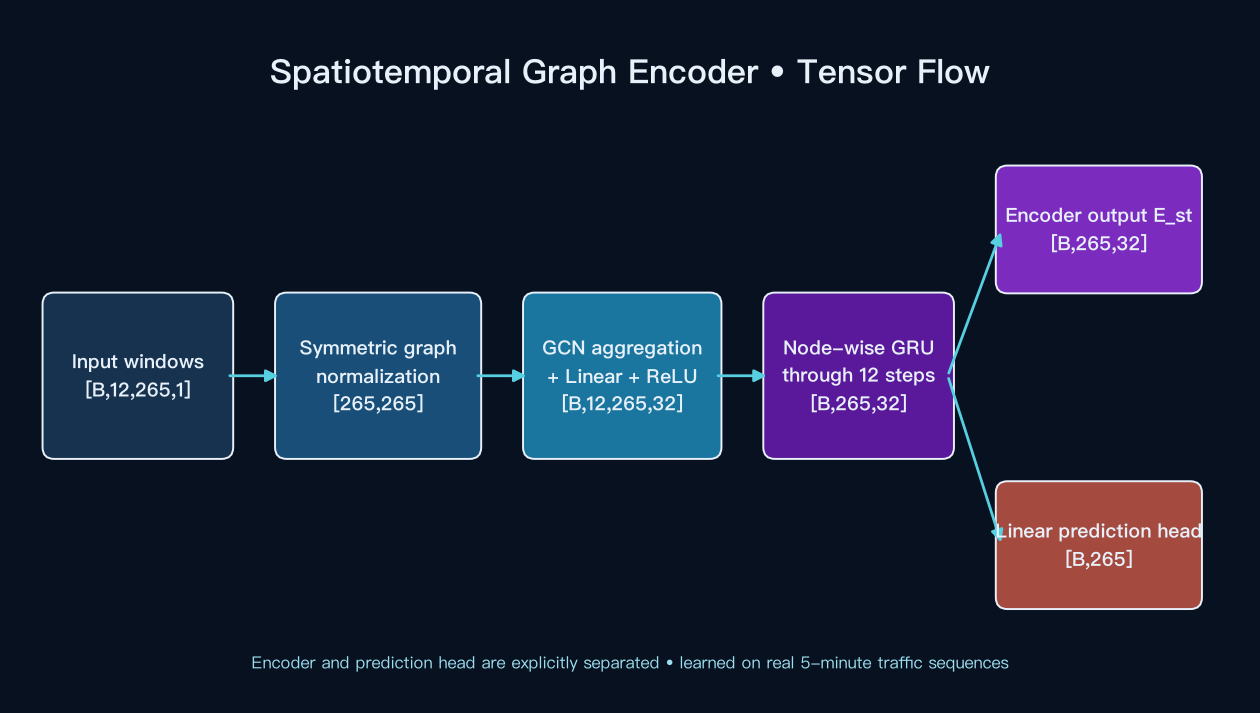

findfont: Failed to find font weight bold for PingFang SC, now using 600.


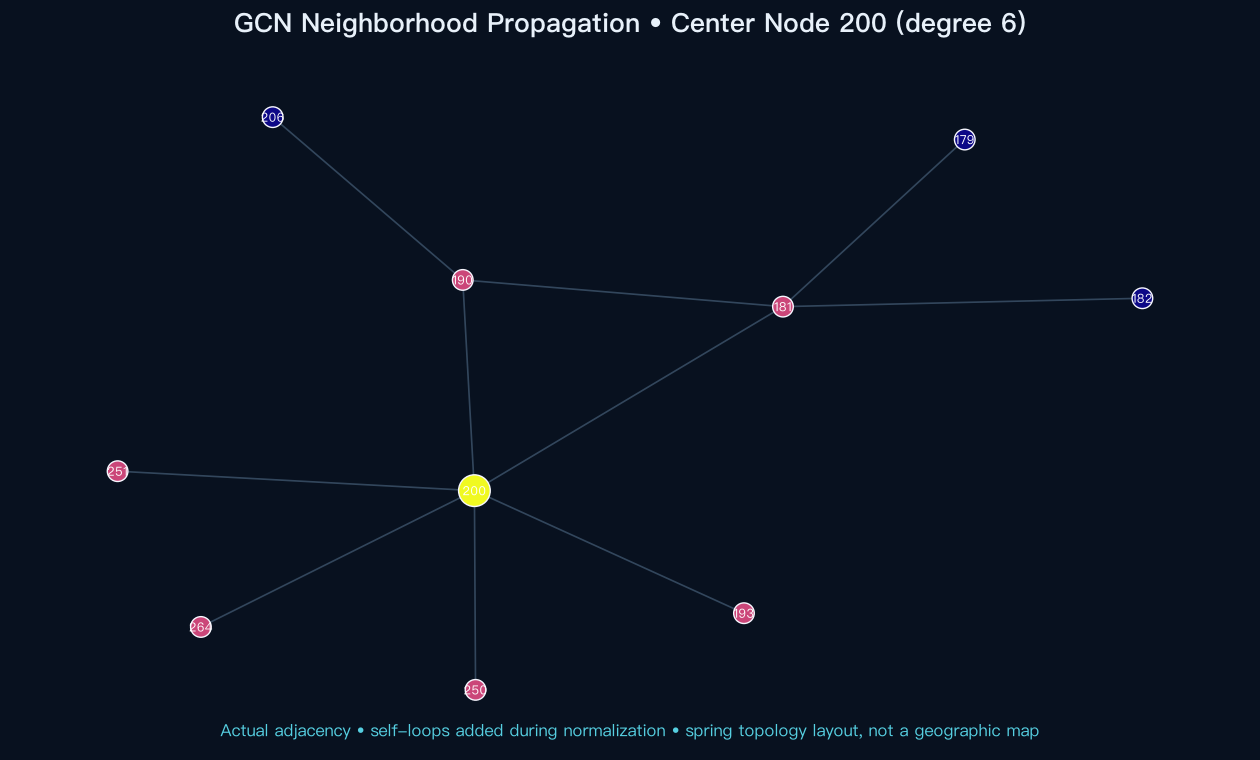

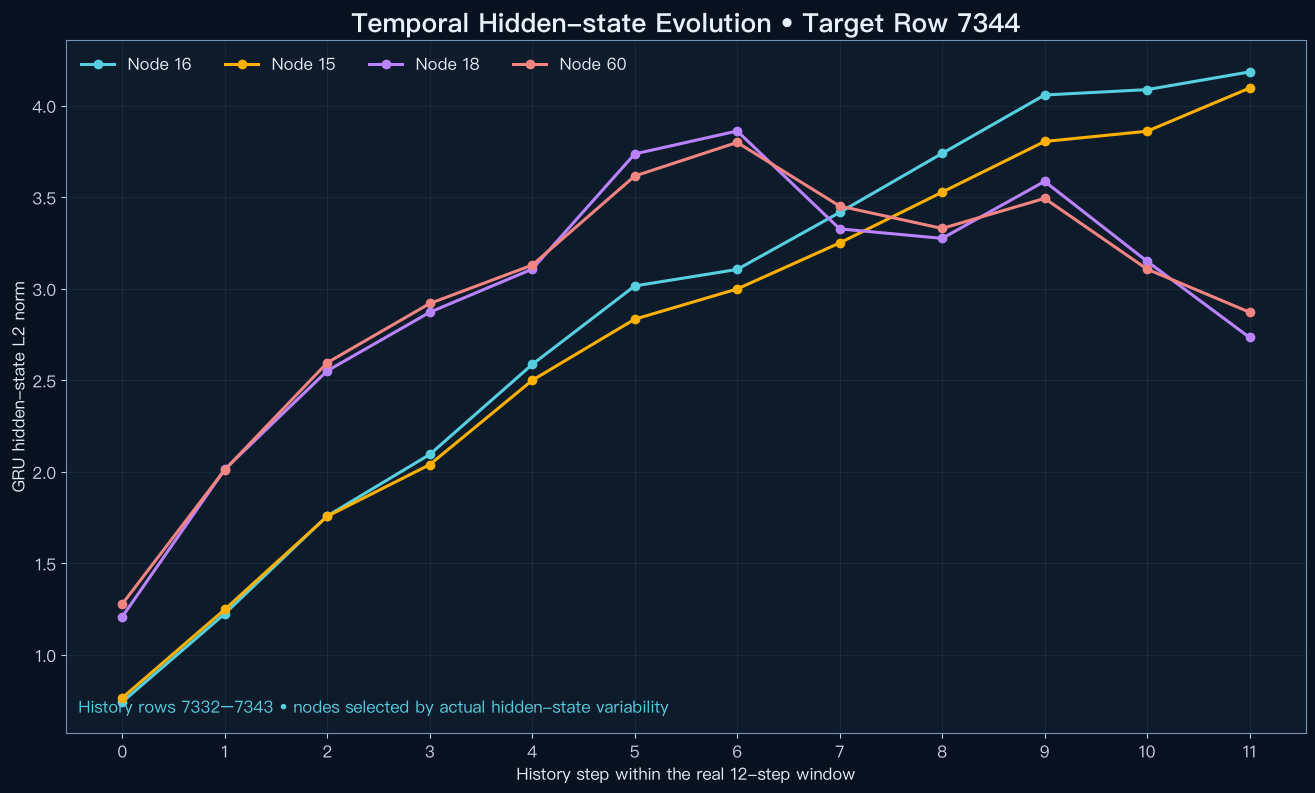

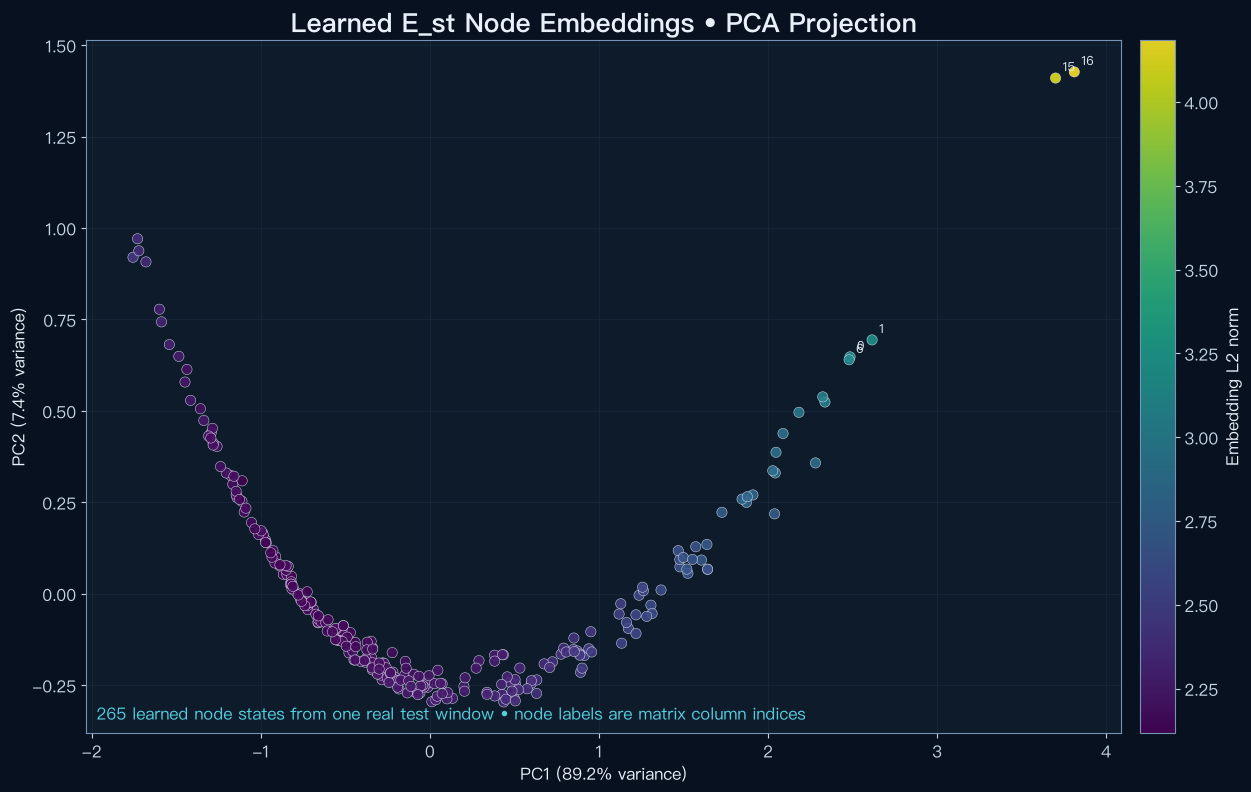

findfont: Failed to find font weight bold for PingFang SC, now using 600.


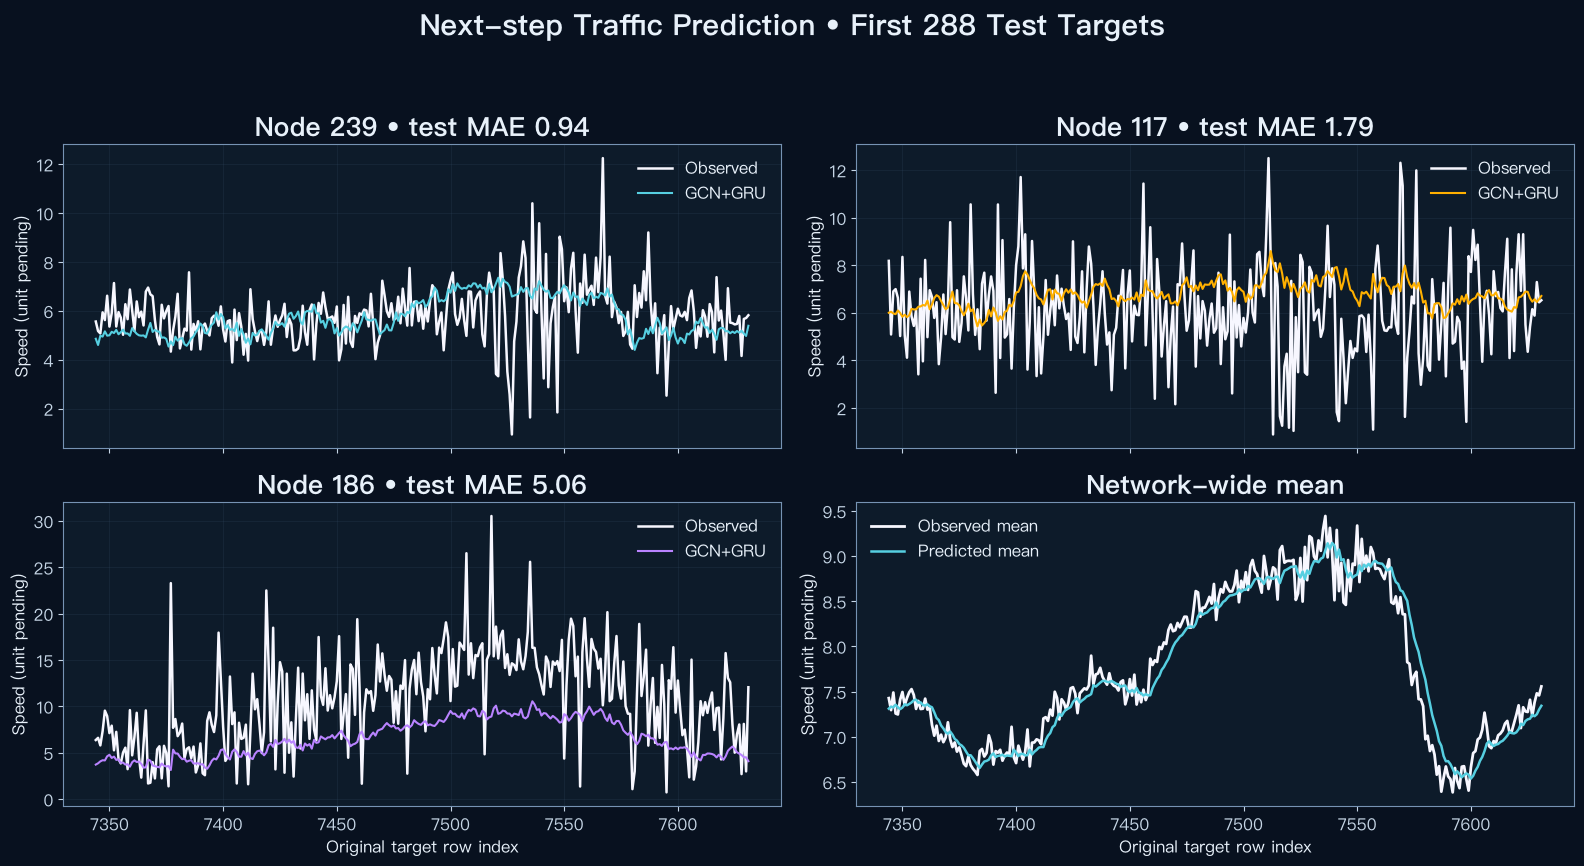

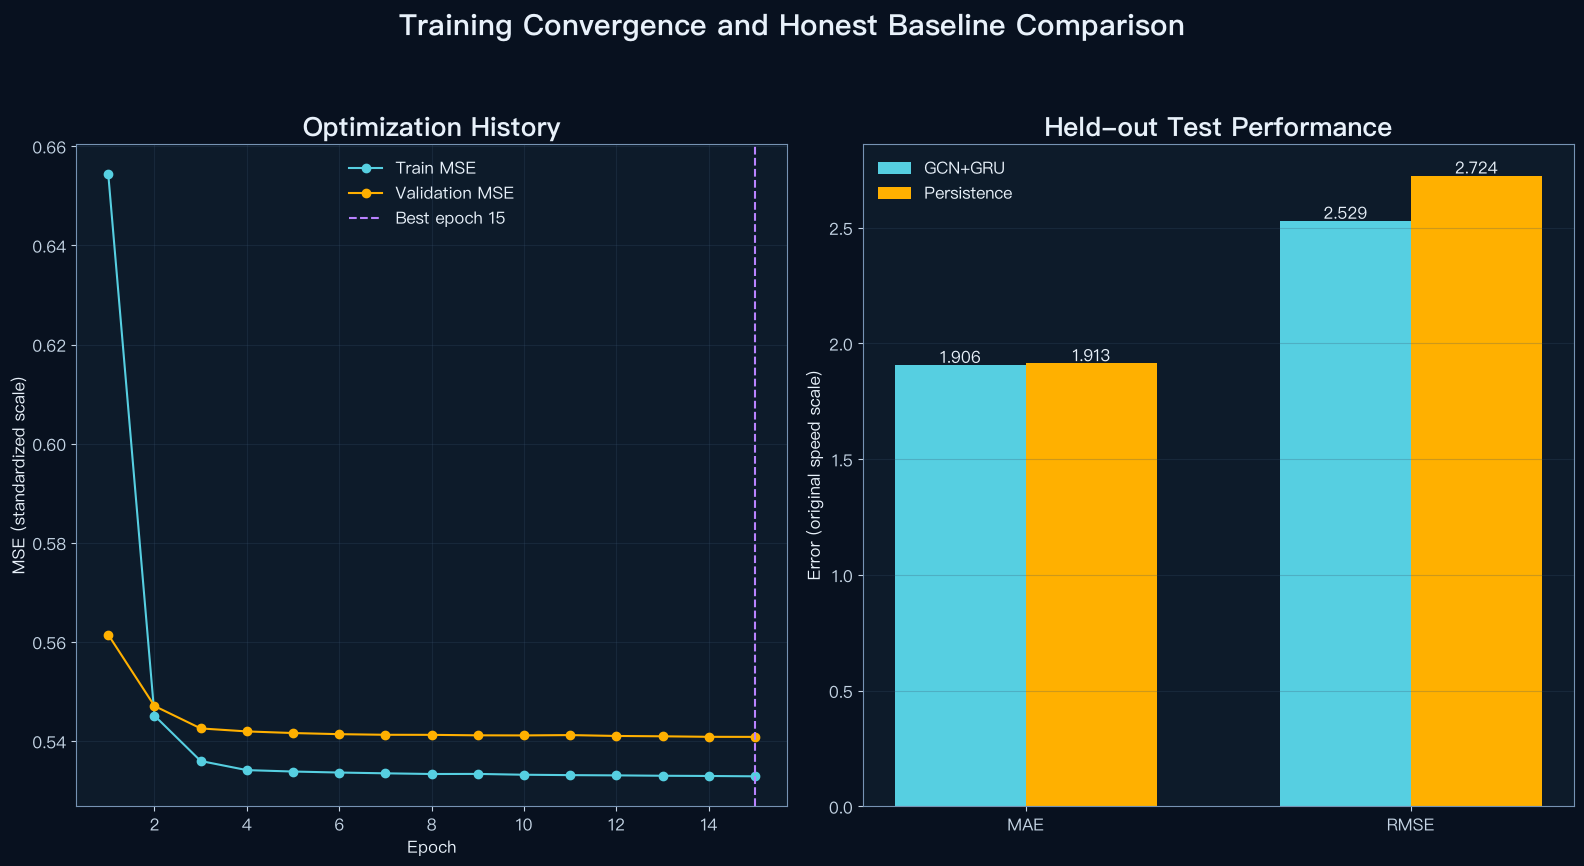

,PNG,SVG
figure_05,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_06,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_07,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_08,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_09,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...
figure_10,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...,/Users/daphne/Desktop/实习/PPT制作/联通项目/urban-join...


In [6]:
figure_outputs=make_step4_figures(ROOT)
display(pd.DataFrame({k:v for k,v in figure_outputs.items()},index=['PNG','SVG']).T)

## 6. 下一阶段接口

后续语义融合可读取 `E_st.npy: float32[265,32]`。其对应预测目标原始行索引和 12 步历史范围由 `E_st_metadata.json` 给出。`node_index` 仅为矩阵列索引，不是地理 FID；不得在恢复映射前把它解释为经纬度或真实网格 ID。